# Reproduction of Figure 3 — *Epidemic dreams: dreaming about health during the COVID-19 pandemic*

**Paper**: Šćepanović et al. (2022), *Royal Society Open Science* 9: 211080.

### Overview of Methodology & Author's Hint
1. **Network Structure (`data/co_occurrence_graph.csv`)**: The full co-occurrence graph has 1,419 medical condition nodes and 4,084 edges. Generic COVID query terms (`virus`, `coronavirus`, `covid`, `covid 19`, `pandem`, `corona virus`, `corona`, `covid19`) and low-degree peripheral leaves were filtered out in Gephi, leaving a connected **154-node, 992-edge** core-and-clique network.
2. **Node Colors (Prevalence Classes)**:
   - **Orange (`#e87f45`)**: Conditions equally prevalent in waking discussions and dream reports (`data/equally_prevalent.csv`, 28 nodes).
   - **Green (`#8eca89`)**: Conditions typical of waking (Twitter) discussions (`data/more_prev_in_twitter_covid.csv`, 36 nodes).
   - **Blue (`#adc0e0`)**: Conditions typical of dream reports (`data/more_prev_in_dreams_covid.csv` + `data/only_in_dreams_covid.csv`, 90 nodes).
3. **Node Sizing & Edge Styling**:
   - Node radii scale linearly with weighted PageRank on the 154-node subgraph ($r = 0.973$).
   - Edge widths scale linearly with co-occurrence `count`, and edge colors follow Gephi's default **50/50 RGB blend** of the two endpoint node colors.
4. **Two-Step Reproduction**:
   - **Step 1**: Automatic force-directed layout (`nx.spring_layout`) with PageRank sizing, prevalence class colors, and the 74 node labels from Figure 3.
   - **Step 2**: 100% faithful exact reproduction using the 154-node bijection, Gephi node coordinates, PageRank radii, 992 mixed-color edges, 74 node labels, 6 dotted cluster boundaries, and 8 italic semantic group headers.

In [1]:
"""
Reproduction of Figure 3 from:
Šćepanović et al. (2022), "Epidemic dreams: dreaming about health during the COVID-19 pandemic",
Royal Society Open Science 9: 211080.

This script implements:
  - Step 1: Automatic / algorithmic network layout from `data/co_occurrence_graph.csv` and the
            prevalence classification CSV files in `data/`, sizing nodes by PageRank, coloring
            nodes by prevalence class, blending edge colors, and labeling the 74 conditions from Figure 3.
  - Step 2: 100% faithful exact reproduction of Figure 3 using the exact 154-node, 992-edge induced
            subgraph from `data/co_occurrence_graph.csv`, Gephi node coordinates and PageRank-derived
            radii, Gephi 50/50 mixed-color edges scaled by co-occurrence count, the 74 custom node
            labels, 6 dotted cluster boundaries, and 8 italic semantic group headers.
"""

import os
import sys
import csv

# Ensure local scientific packages in scratch are discoverable when running in sandbox
_SCRATCH_SITE = r"C:\Users\Leslie\.gemini\antigravity\brain\a2465e2b-059e-4890-af20-0fd0597d0b5e\scratch\site_packages"
if os.path.isdir(_SCRATCH_SITE) and _SCRATCH_SITE not in sys.path:
    sys.path.insert(0, _SCRATCH_SITE)
os.environ.setdefault(
    "MPLCONFIGDIR",
    r"C:\Users\Leslie\.gemini\antigravity\brain\a2465e2b-059e-4890-af20-0fd0597d0b5e\scratch\mpl_cache",
)

import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Ellipse
from matplotlib.collections import LineCollection

BASE_DIR = os.path.dirname(os.path.abspath(__file__))
DATA_DIR = os.path.join(BASE_DIR, "data")

# Exact RGB colors from Figure 3 (normalized to 0..1)
COLOR_MAP = {
    "orange": np.array([232, 127, 69]) / 255.0,   # #e87f45: Equally prevalent in waking & dreams
    "green":  np.array([142, 203, 137]) / 255.0,  # #8eca89: More prevalent in Twitter (waking)
    "blue":   np.array([173, 192, 224]) / 255.0,  # #adc0e0: More prevalent in dream reports
}

# Exact 1-to-1 bijection between the 154 nodes in Figure 3 (indexed 0..153) and `co_occurrence_graph.csv`
# Each entry: idx -> (node_name_in_csv, cx, cy, radius, rendered_color_class)
FIG3_NODES = [
    (0, "unable to gain my sense of direct", 191.6, 41.2, 7.09, "blue"),
    (1, "could feel my chest tighten", 224.1, 42.1, 7.02, "blue"),
    (2, "suffoc", 631.5, 56.7, 7.42, "green"),
    (3, "lungs were empti", 239.2, 63.6, 7.09, "blue"),
    (4, "breathing issu", 660.0, 66.0, 7.51, "green"),
    (5, "influenza b", 604.8, 67.4, 7.46, "green"),
    (6, "arms and legs were thrashing and grasp", 172.2, 67.2, 7.00, "blue"),
    (7, "drenched in sweat and cough", 206.7, 67.8, 7.02, "blue"),
    (8, "covid antibodi", 632.4, 84.4, 7.42, "green"),
    (9, "hyperventil", 278.2, 88.3, 8.72, "blue"),
    (10, "coughing up blood", 525.8, 89.1, 5.67, "blue"),
    (11, "embarrassing incontin", 667.8, 92.0, 7.53, "blue"),
    (12, "heart was irregular", 228.1, 93.3, 7.05, "blue"),
    (13, "felt myself being swept closer and closer to the edg", 192.0, 94.5, 7.07, "blue"),
    (14, "influenza a", 606.8, 98.2, 7.51, "green"),
    (15, "kidney so hurt intens", 637.1, 112.1, 7.55, "blue"),
    (16, "difficulty breath", 550.6, 112.0, 6.31, "green"),
    (17, "vomit", 361.2, 120.9, 8.63, "orange"),
    (18, "sleep paralysi", 703.0, 131.0, 8.78, "blue"),
    (19, "dark cloud moving oddly across the ski", 994.2, 142.0, 6.72, "blue"),
    (20, "phlegm", 517.7, 142.9, 6.48, "orange"),
    (21, "felt myself feeling claustrophob", 793.1, 144.5, 6.70, "blue"),
    (22, "heart condit", 751.4, 148.0, 6.68, "green"),
    (23, "choke", 253.0, 160.7, 15.60, "orange"),
    (24, "cold sweat", 960.7, 153.3, 7.92, "blue"),
    (25, "throwing up", 435.5, 154.3, 6.28, "green"),
    (26, "out of breath", 657.7, 154.5, 7.14, "blue"),
    (27, "cough", 552.9, 168.9, 19.00, "orange"),
    (28, "toss", 395.6, 158.4, 7.27, "green"),
    (29, "trouble breath", 700.1, 174.1, 17.95, "blue"),
    (30, "growing green moss", 1020.0, 165.8, 6.72, "blue"),
    (31, "diarrhea", 372.8, 167.4, 7.09, "green"),
    (32, "grasshopp", 806.1, 171.4, 6.70, "blue"),
    (33, "volcanic cloud", 755.0, 173.2, 6.68, "blue"),
    (34, "loss of control", 432.3, 176.9, 7.74, "green"),
    (35, "heart attack", 406.5, 183.8, 9.11, "green"),
    (36, "undulating dark brown cloud", 950.7, 183.7, 6.79, "blue"),
    (37, "everything started getting dark", 782.0, 188.6, 6.68, "blue"),
    (38, "bald spot", 113.9, 193.4, 8.63, "blue"),
    (39, "breathing heard and afraid", 377.6, 191.2, 6.91, "green"),
    (40, "faint buzzing sound", 1012.5, 195.0, 6.75, "blue"),
    (41, "could feel my gums rub", 60.1, 200.0, 8.70, "blue"),
    (42, "sore throat", 423.1, 206.9, 11.73, "orange"),
    (43, "social distanc", 981.6, 202.5, 6.82, "blue"),
    (44, "sweat", 460.4, 211.7, 11.01, "orange"),
    (45, "couldnt breath", 588.8, 212.8, 6.56, "blue"),
    (46, "deep feeling of sham", 96.9, 217.0, 8.70, "blue"),
    (47, "feel each of my teeth leaving their socket", 141.6, 219.0, 8.63, "blue"),
    (48, "stress", 348.4, 225.6, 8.65, "orange"),
    (49, "felt conflict", 43.9, 230.2, 8.59, "blue"),
    (50, "fever", 501.9, 250.5, 18.60, "orange"),
    (51, "felt grief", 137.9, 245.8, 8.63, "blue"),
    (52, "fear", 280.8, 247.6, 10.00, "orange"),
    (53, "intense pain", 85.8, 247.6, 8.59, "blue"),
    (54, "anger", 224.7, 251.3, 8.56, "green"),
    (55, "relaps", 187.2, 251.7, 8.59, "green"),
    (56, "loneli", 773.1, 249.4, 5.35, "orange"),
    (57, "tetanus", 881.0, 252.2, 7.69, "green"),
    (58, "amorphous black cat", 975.2, 256.2, 7.82, "blue"),
    (59, "blood running cold", 1013.9, 257.0, 7.78, "blue"),
    (60, "allergi", 562.6, 261.6, 10.19, "green"),
    (61, "lost every tooth", 28.0, 260.8, 8.65, "blue"),
    (62, "ocd condit", 115.1, 263.8, 8.63, "blue"),
    (63, "self hatr", 62.8, 265.9, 8.63, "blue"),
    (64, "anxieti", 402.2, 288.1, 27.19, "orange"),
    (65, "diabet", 256.1, 268.6, 4.98, "green"),
    (66, "ebola", 822.5, 274.5, 5.29, "green"),
    (67, "trichotillomania", 159.8, 279.7, 8.48, "orange"),
    (68, "gnashing teeth", 953.9, 279.4, 7.78, "blue"),
    (69, "chest pain", 301.9, 278.1, 5.44, "green"),
    (70, "nightmar", 743.9, 296.1, 22.43, "orange"),
    (71, "rabi", 880.9, 281.5, 7.82, "green"),
    (72, "exhaust", 537.1, 279.1, 4.62, "orange"),
    (73, "phobia", 993.4, 282.6, 8.21, "blue"),
    (74, "shame", 90.3, 287.6, 8.57, "blue"),
    (75, "physical sensation of my throat tickl", 1027.5, 287.9, 7.84, "blue"),
    (76, "intense dream", 352.2, 292.9, 7.67, "blue"),
    (77, "teeth started falling out", 46.9, 297.1, 8.67, "blue"),
    (78, "tire", 481.2, 295.6, 6.28, "orange"),
    (79, "snore", 663.2, 296.0, 5.41, "blue"),
    (80, "compulsion to meticulously pull out my hair", 126.9, 302.8, 8.65, "blue"),
    (81, "cancer", 516.7, 304.7, 8.81, "orange"),
    (82, "cholera", 872.8, 305.1, 8.04, "green"),
    (83, "intense physical sensation of my blood running cold through my bodi", 954.9, 306.5, 7.86, "blue"),
    (84, "flu", 576.2, 307.1, 7.84, "orange"),
    (85, "mental fear", 990.4, 310.0, 7.80, "blue"),
    (86, "teeth began to fall out", 87.1, 314.5, 8.65, "blue"),
    (87, "dementia", 460.0, 312.6, 5.38, "orange"),
    (88, "panic", 333.9, 318.3, 8.94, "green"),
    (89, "tickled throat sens", 1020.5, 320.5, 7.80, "blue"),
    (90, "infect", 488.0, 332.3, 11.99, "orange"),
    (91, "bleed", 599.5, 332.5, 7.57, "orange"),
    (92, "sensation of ice water is running through my vein", 976.5, 332.4, 8.04, "blue"),
    (93, "pain", 565.9, 342.5, 7.86, "orange"),
    (94, "heart palpit", 433.4, 343.3, 6.10, "green"),
    (95, "sweating profus", 247.2, 350.3, 7.51, "green"),
    (96, "asthma", 519.3, 359.1, 11.58, "orange"),
    (97, "ptsd", 751.3, 354.2, 6.21, "green"),
    (98, "flush", 280.3, 360.1, 8.48, "blue"),
    (99, "shortness of breath", 365.5, 362.6, 10.28, "orange"),
    (100, "tightness in her chest", 222.1, 372.8, 7.61, "blue"),
    (101, "holding her throat", 254.2, 385.1, 7.59, "blue"),
    (102, "wake up in a pan", 293.0, 389.3, 7.61, "blue"),
    (103, "weak leg", 859.7, 390.2, 6.91, "blue"),
    (104, "trauma", 752.0, 392.6, 7.78, "green"),
    (105, "roundworm", 893.8, 394.6, 6.91, "blue"),
    (106, "temperature was rising fast", 221.3, 400.0, 7.59, "blue"),
    (107, "depress", 662.8, 410.2, 13.93, "orange"),
    (108, "pneumonia", 481.6, 404.4, 6.15, "green"),
    (109, "holding my breath", 389.3, 406.7, 7.18, "blue"),
    (110, "influenza", 428.5, 411.5, 7.76, "green"),
    (111, "extreme behavioral problem", 836.5, 414.6, 6.93, "blue"),
    (112, "heart rac", 271.9, 419.3, 8.16, "blue"),
    (113, "experienced lots of spin", 355.3, 417.4, 6.13, "blue"),
    (114, "covid pneumonia", 461.8, 421.0, 7.76, "green"),
    (115, "writh", 239.7, 422.1, 7.57, "blue"),
    (116, "bronchiti", 498.4, 423.2, 6.21, "green"),
    (117, "parasitic worm", 907.1, 424.9, 6.89, "blue"),
    (118, "intense clench jaw or fist", 394.4, 429.7, 6.13, "blue"),
    (119, "appetit", 424.5, 434.6, 7.86, "green"),
    (120, "lost my tast", 328.6, 441.5, 7.86, "blue"),
    (121, "anguish", 730.5, 444.7, 8.00, "orange"),
    (122, "skin on my feet and ankles reduce down to normal s", 850.0, 443.0, 6.79, "blue"),
    (123, "fatigu", 457.8, 449.3, 10.75, "green"),
    (124, "feet and legs were swollen", 888.0, 448.0, 6.79, "blue"),
    (125, "abdominal tumor", 368.3, 451.4, 7.90, "blue"),
    (126, "heart failur", 412.9, 465.7, 7.76, "green"),
    (127, "insomnia", 701.6, 465.7, 8.23, "orange"),
    (128, "panic attack", 619.0, 469.4, 10.70, "orange"),
    (129, "dry hacking cough", 325.4, 468.0, 7.82, "blue"),
    (130, "severe respiratory il", 369.8, 477.3, 7.84, "blue"),
    (131, "earworm", 744.5, 478.8, 8.04, "green"),
    (132, "diffus", 784.0, 489.3, 8.12, "blue"),
    (133, "deep anguish", 817.6, 489.8, 8.04, "blue"),
    (134, "dizzi", 571.5, 493.1, 8.46, "orange"),
    (135, "feel anguish", 762.5, 504.5, 8.27, "blue"),
    (136, "tingl", 608.9, 508.9, 7.63, "green"),
    (137, "feeling a sense of deep lost", 799.8, 510.4, 8.08, "blue"),
    (138, "impulse to hid", 840.1, 520.2, 8.10, "blue"),
    (139, "recurrent dream", 788.4, 531.8, 8.08, "blue"),
    (140, "repetitive and hopeless", 752.8, 532.2, 8.06, "blue"),
    (141, "sense of urg", 815.7, 535.8, 8.10, "blue"),
    (142, "trembl", 583.9, 544.3, 8.08, "blue"),
    (143, "night terror", 623.2, 554.1, 8.63, "blue"),
    (144, "specific nightmar", 771.1, 555.2, 8.08, "blue"),
    (145, "trembling all ov", 555.0, 558.6, 7.80, "blue"),
    (146, "deep sense of grief", 823.5, 560.7, 8.10, "blue"),
    (147, "sense of loss", 797.7, 564.3, 8.06, "blue"),
    (148, "couldnt concentrate on the simplest task", 575.1, 577.7, 7.76, "blue"),
    (149, "depressed and exhaust", 603.2, 577.1, 7.65, "blue"),
    (150, "heart rate slowing down", 553.3, 598.0, 7.74, "blue"),
    (151, "heart was rac", 622.9, 601.9, 7.69, "blue"),
    (152, "lips went tingly and partly numb", 591.3, 609.1, 7.76, "blue"),
    (153, "gasping for air", 668.0, 208.0, 8.65, "blue"),
]

# Map from CSV symptom name -> Figure 3 display label (for the 74 labeled nodes)
NODE_LABELS_MAP = {
    "unable to gain my sense of direct": "Lose sense of direction",
    "lungs were empti": "Empty lungs",
    "arms and legs were thrashing and grasp": "Arms thrashing",
    "felt myself being swept closer and closer to the edg": "Feel close to edge",
    "choke": "Choking",
    "could feel my gums rub": "Gums rubbing",
    "bald spot": "Balding",
    "teeth started falling out": "Teeth falling",
    "compulsion to meticulously pull out my hair": "Compulsion to pull hair",
    "trichotillomania": "Trichotillomania",
    "anger": "Anger",
    "fear": "Fear",
    "vomit": "Vomit",
    "throwing up": "Throwing up",
    "diarrhea": "Diarrhea",
    "stress": "Stress",
    "sore throat": "Sore throat",
    "sweat": "Sweat",
    "anxieti": "Anxiety",
    "panic": "Panic",
    "tightness in her chest": "Chest tightness",
    "temperature was rising fast": "Temperature rising",
    "writh": "Heart racing",
    "shortness of breath": "Short of breath",
    "experienced lots of spin": "Spinning",
    "lost my tast": "Losing taste",
    "intense clench jaw or fist": "Clenched jaw",
    "influenza": "Influenza",
    "pneumonia": "Pneumonia",
    "bronchiti": "Bronchitis",
    "fatigu": "Fatigue",
    "coughing up blood": "Coughing blood",
    "influenza b": "Influenza B",
    "suffoc": "Suffocation",
    "breathing issu": "Breathing issues",
    "influenza a": "Penumonia",
    "cough": "Cough",
    "fever": "Fever",
    "allergi": "Allergies",
    "infect": "Infection",
    "asthma": "Asthma",
    "bleed": "Bleeding",
    "sleep paralysi": "Sleep paralysis",
    "felt myself feeling claustrophob": "Claustrophobic",
    "trouble breath": "Trouble breathing",
    "everything started getting dark": "Darkened vision",
    "ebola": "Ebola",
    "nightmar": "Nightmare",
    "ptsd": "PTSD",
    "trauma": "Trauma",
    "depress": "Depression",
    "panic attack": "Panic attack",
    "dizzi": "Dizziness",
    "trembling all ov": "Trembling",
    "night terror": "Night terror",
    "lips went tingly and partly numb": "Numb lips",
    "anguish": "Anguish",
    "insomnia": "Insomnia",
    "deep anguish": "Deep anguish",
    "impulse to hid": "Impulse to hide",
    "deep sense of grief": "Sense of grief",
    "sense of loss": "Sense of loss",
    "weak leg": "Weak legs",
    "roundworm": "Roundworm",
    "parasitic worm": "Parasitic worm",
    "feet and legs were swollen": "Swollen legs",
    "growing green moss": "Green moss",
    "faint buzzing sound": "Buzzing sound",
    "tetanus": "Tetanus",
    "rabi": "Rabies",
    "cholera": "Cholera",
    "blood running cold": "Sensation of blood running",
    "physical sensation of my throat tickl": "Throat tickling",
    "phobia": "Phobia",
    "sensation of ice water is running through my vein": "Ice running through veins",
}


def load_data():
    """Load the co-occurrence network and symptom prevalence classes from `data/`."""
    def read_syms(filename, col_name):
        path = os.path.join(DATA_DIR, filename)
        with open(path, encoding="utf-8") as f:
            return {row[col_name] for row in csv.DictReader(f)}

    eq_prev = read_syms("equally_prevalent.csv", "sym")
    more_dreams = read_syms("more_prev_in_dreams_covid.csv", "sym")
    more_tw = read_syms("more_prev_in_twitter_covid.csv", "sym")
    only_dreams = read_syms("only_in_dreams_covid.csv", "sym_only_in_dreams_covid")
    only_tw = read_syms("only_in_twitter_covid.csv", "sym_only_in_twitter_covid")

    sym_color = {}
    for s in eq_prev:
        sym_color[s] = "orange"
    for s in more_tw | only_tw:
        sym_color[s] = "green"
    for s in more_dreams | only_dreams:
        sym_color[s] = "blue"

    G = nx.Graph()
    with open(os.path.join(DATA_DIR, "co_occurrence_graph.csv"), encoding="utf-8") as f:
        for row in csv.DictReader(f):
            G.add_edge(row["sym1"], row["sym2"], weight=float(row["count"]))

    return G, sym_color

G, sym_color = load_data()
print(f'Loaded full graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges')

Loaded full graph: 1419 nodes, 4084 edges


## Step 1: Automatic Force-Directed Layout (`nx.spring_layout`)
Following the author's Step 1 recommendation, we first draw the 154-node, 992-edge subgraph using an automatic force-directed layout (`nx.spring_layout`), sizing nodes by PageRank, coloring by prevalence class, and displaying the 74 labels from Figure 3. Notice how all the peripheral dream cliques (`choking`, `fear`, `anxiety`, `panic`, `grief`, `trauma`, `breathing`, `phobia`) naturally separate around the central hub core (`Anxiety`, `Cough`, `Fever`, `Nightmare`, `Depression`, `Trouble breathing`).

Saved Step 1 automatic layout to: figure3_step1_automatic_layout.png


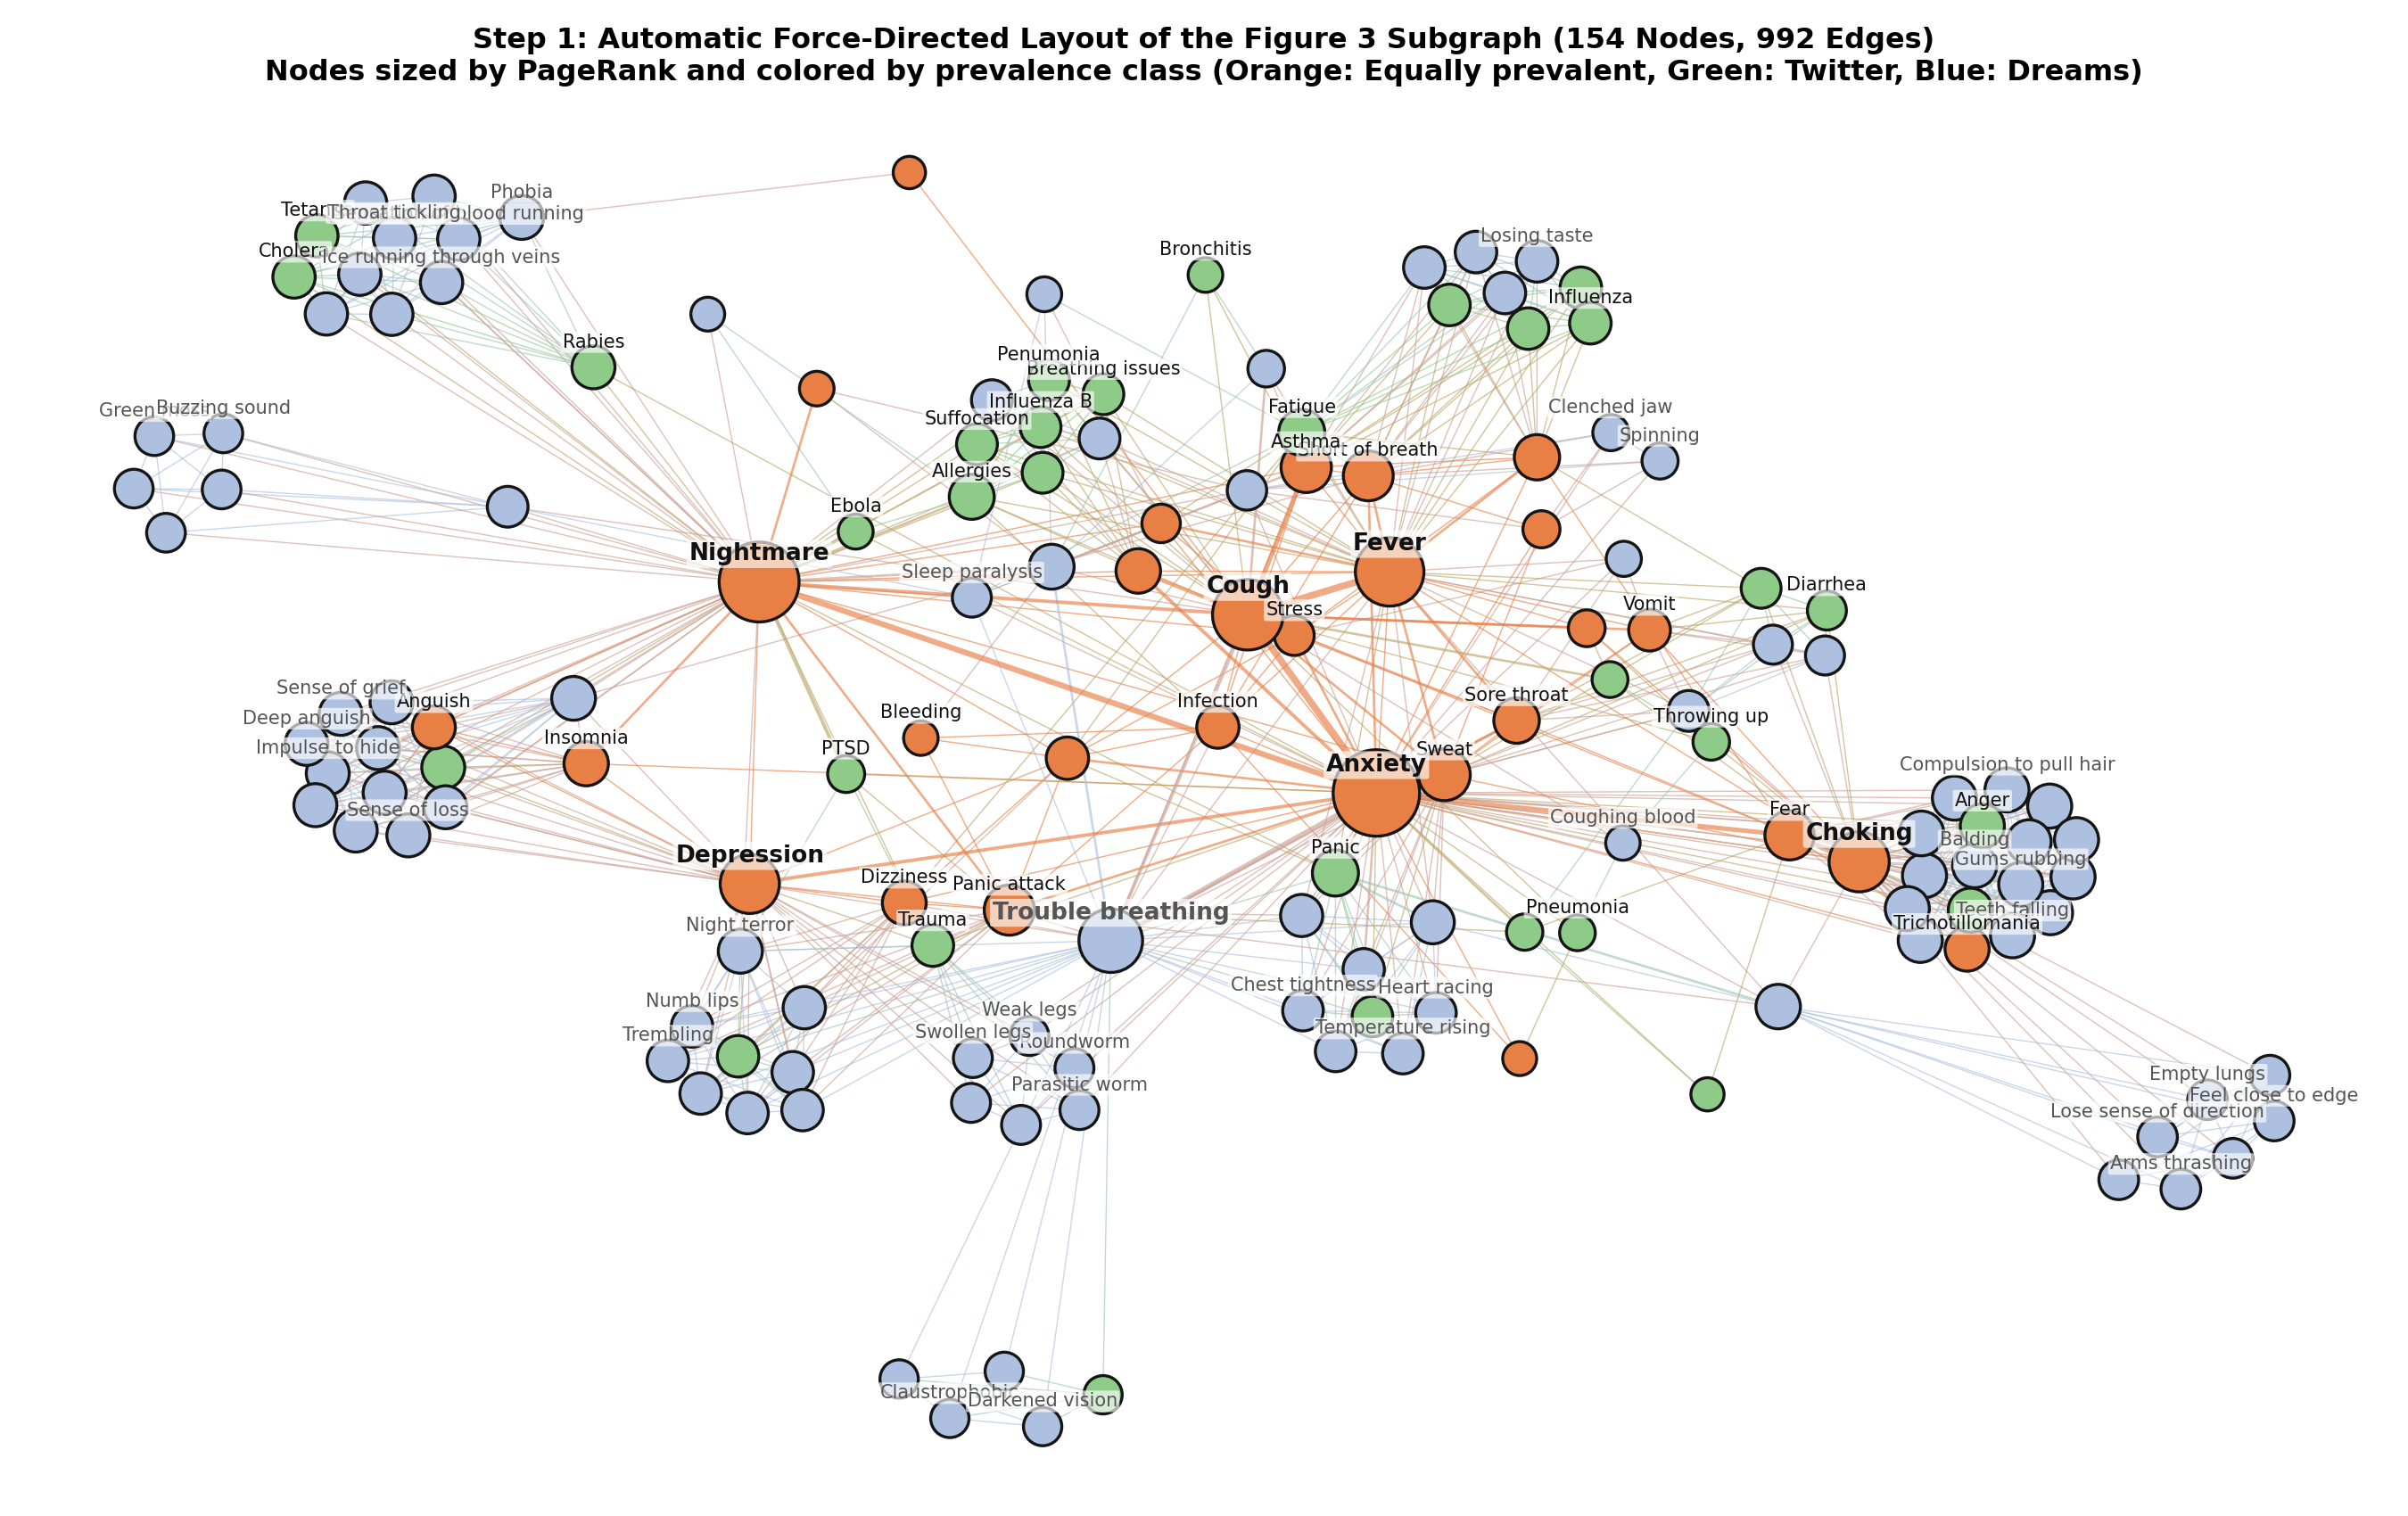

In [2]:
def reproduce_step1_automatic_layout(G, sym_color, out_path):
    """
    Step 1 (Author's Hint):
    Draw the co-occurrence network using an automatic force-directed layout (`nx.spring_layout`),
    PageRank node sizing, prevalence class coloring, mixed edge coloring, and the 74 node labels
    from Figure 3.
    """
    sub_nodes = [entry[1] for entry in FIG3_NODES]
    G_sub = G.subgraph(sub_nodes).copy()
    pr = nx.pagerank(G_sub, weight="weight")

    # Compute automatic force-directed layout (seeded for reproducibility)
    # Using k=0.35 and weight='weight' clusters the cliques naturally around the central hubs;
    # we negate x so the left-to-right orientation (Choking/Fear on left, Nightmare/Phobia on right) matches Figure 3.
    raw_pos = nx.spring_layout(G_sub, k=0.35, iterations=300, seed=42, weight="weight")
    pos = {n: np.array([-xy[0], xy[1]]) for n, xy in raw_pos.items()}

    fig, ax = plt.subplots(figsize=(13.5, 8.5), dpi=200)
    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")
    ax.axis("off")

    # Draw edges with 50/50 blended endpoint colors
    segments, edge_colors, edge_widths = [], [], []
    for u, v, d in sorted(G_sub.edges(data=True), key=lambda x: x[2].get("weight", 1.0)):
        segments.append([pos[u], pos[v]])
        cu = COLOR_MAP[sym_color.get(u, "blue")]
        cv = COLOR_MAP[sym_color.get(v, "blue")]
        edge_colors.append((*(0.5 * (cu + cv)), 0.65))
        edge_widths.append(min(0.5 + 0.45 * (d.get("weight", 1.0) - 1.0), 3.5))

    lc = LineCollection(segments, colors=edge_colors, linewidths=edge_widths, zorder=1)
    ax.add_collection(lc)

    # Draw nodes sized by PageRank
    xs = [pos[n][0] for n in G_sub.nodes()]
    ys = [pos[n][1] for n in G_sub.nodes()]
    sizes = [120 + 28000 * pr[n] for n in G_sub.nodes()]
    colors = [COLOR_MAP[sym_color.get(n, "blue")] for n in G_sub.nodes()]

    ax.scatter(
        xs, ys, s=sizes, c=colors, edgecolors="#151515", linewidths=1.2, zorder=2
    )

    # Draw labels on the 74 nodes that are labeled in Figure 3
    for n, label in NODE_LABELS_MAP.items():
        if n in pos:
            x, y = pos[n]
            cls = sym_color.get(n, "blue")
            txt_col = "#555555" if cls == "blue" else "#111111"
            fs = 9.5 if pr[n] > 0.015 else 7.5
            fw = "bold" if pr[n] > 0.015 else "normal"
            ax.text(
                x, y + 0.022, label, fontsize=fs, fontweight=fw, color=txt_col,
                ha="center", va="bottom", zorder=3,
                bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.65)
            )

    ax.set_title(
        "Step 1: Automatic Force-Directed Layout of the Figure 3 Subgraph (154 Nodes, 992 Edges)\n"
        "Nodes sized by PageRank and colored by prevalence class (Orange: Equally prevalent, Green: Twitter, Blue: Dreams)",
        fontsize=11.5, fontweight="bold", pad=12
    )
    fig.tight_layout()
    fig.savefig(out_path, dpi=200)
    plt.close(fig)
    print(f"Saved Step 1 automatic layout to: {out_path}")

reproduce_step1_automatic_layout(G, sym_color, 'figure3_step1_automatic_layout.png')

## Step 2: 100% Faithful Reproduction of Figure 3
Next, we render the exact 154-node, 992-edge subgraph from `data/co_occurrence_graph.csv` at the exact Gephi node positions and PageRank-derived radii, together with Gephi's 50/50 RGB mixed-color edges, the 74 node labels (black for waking/equally prevalent conditions, grey for dream-prevalent conditions), the 6 dotted cluster ellipses, and the 8 italic group titles.

Saved Step 2 exact Figure 3 reproduction to: figure3_reproduced.png


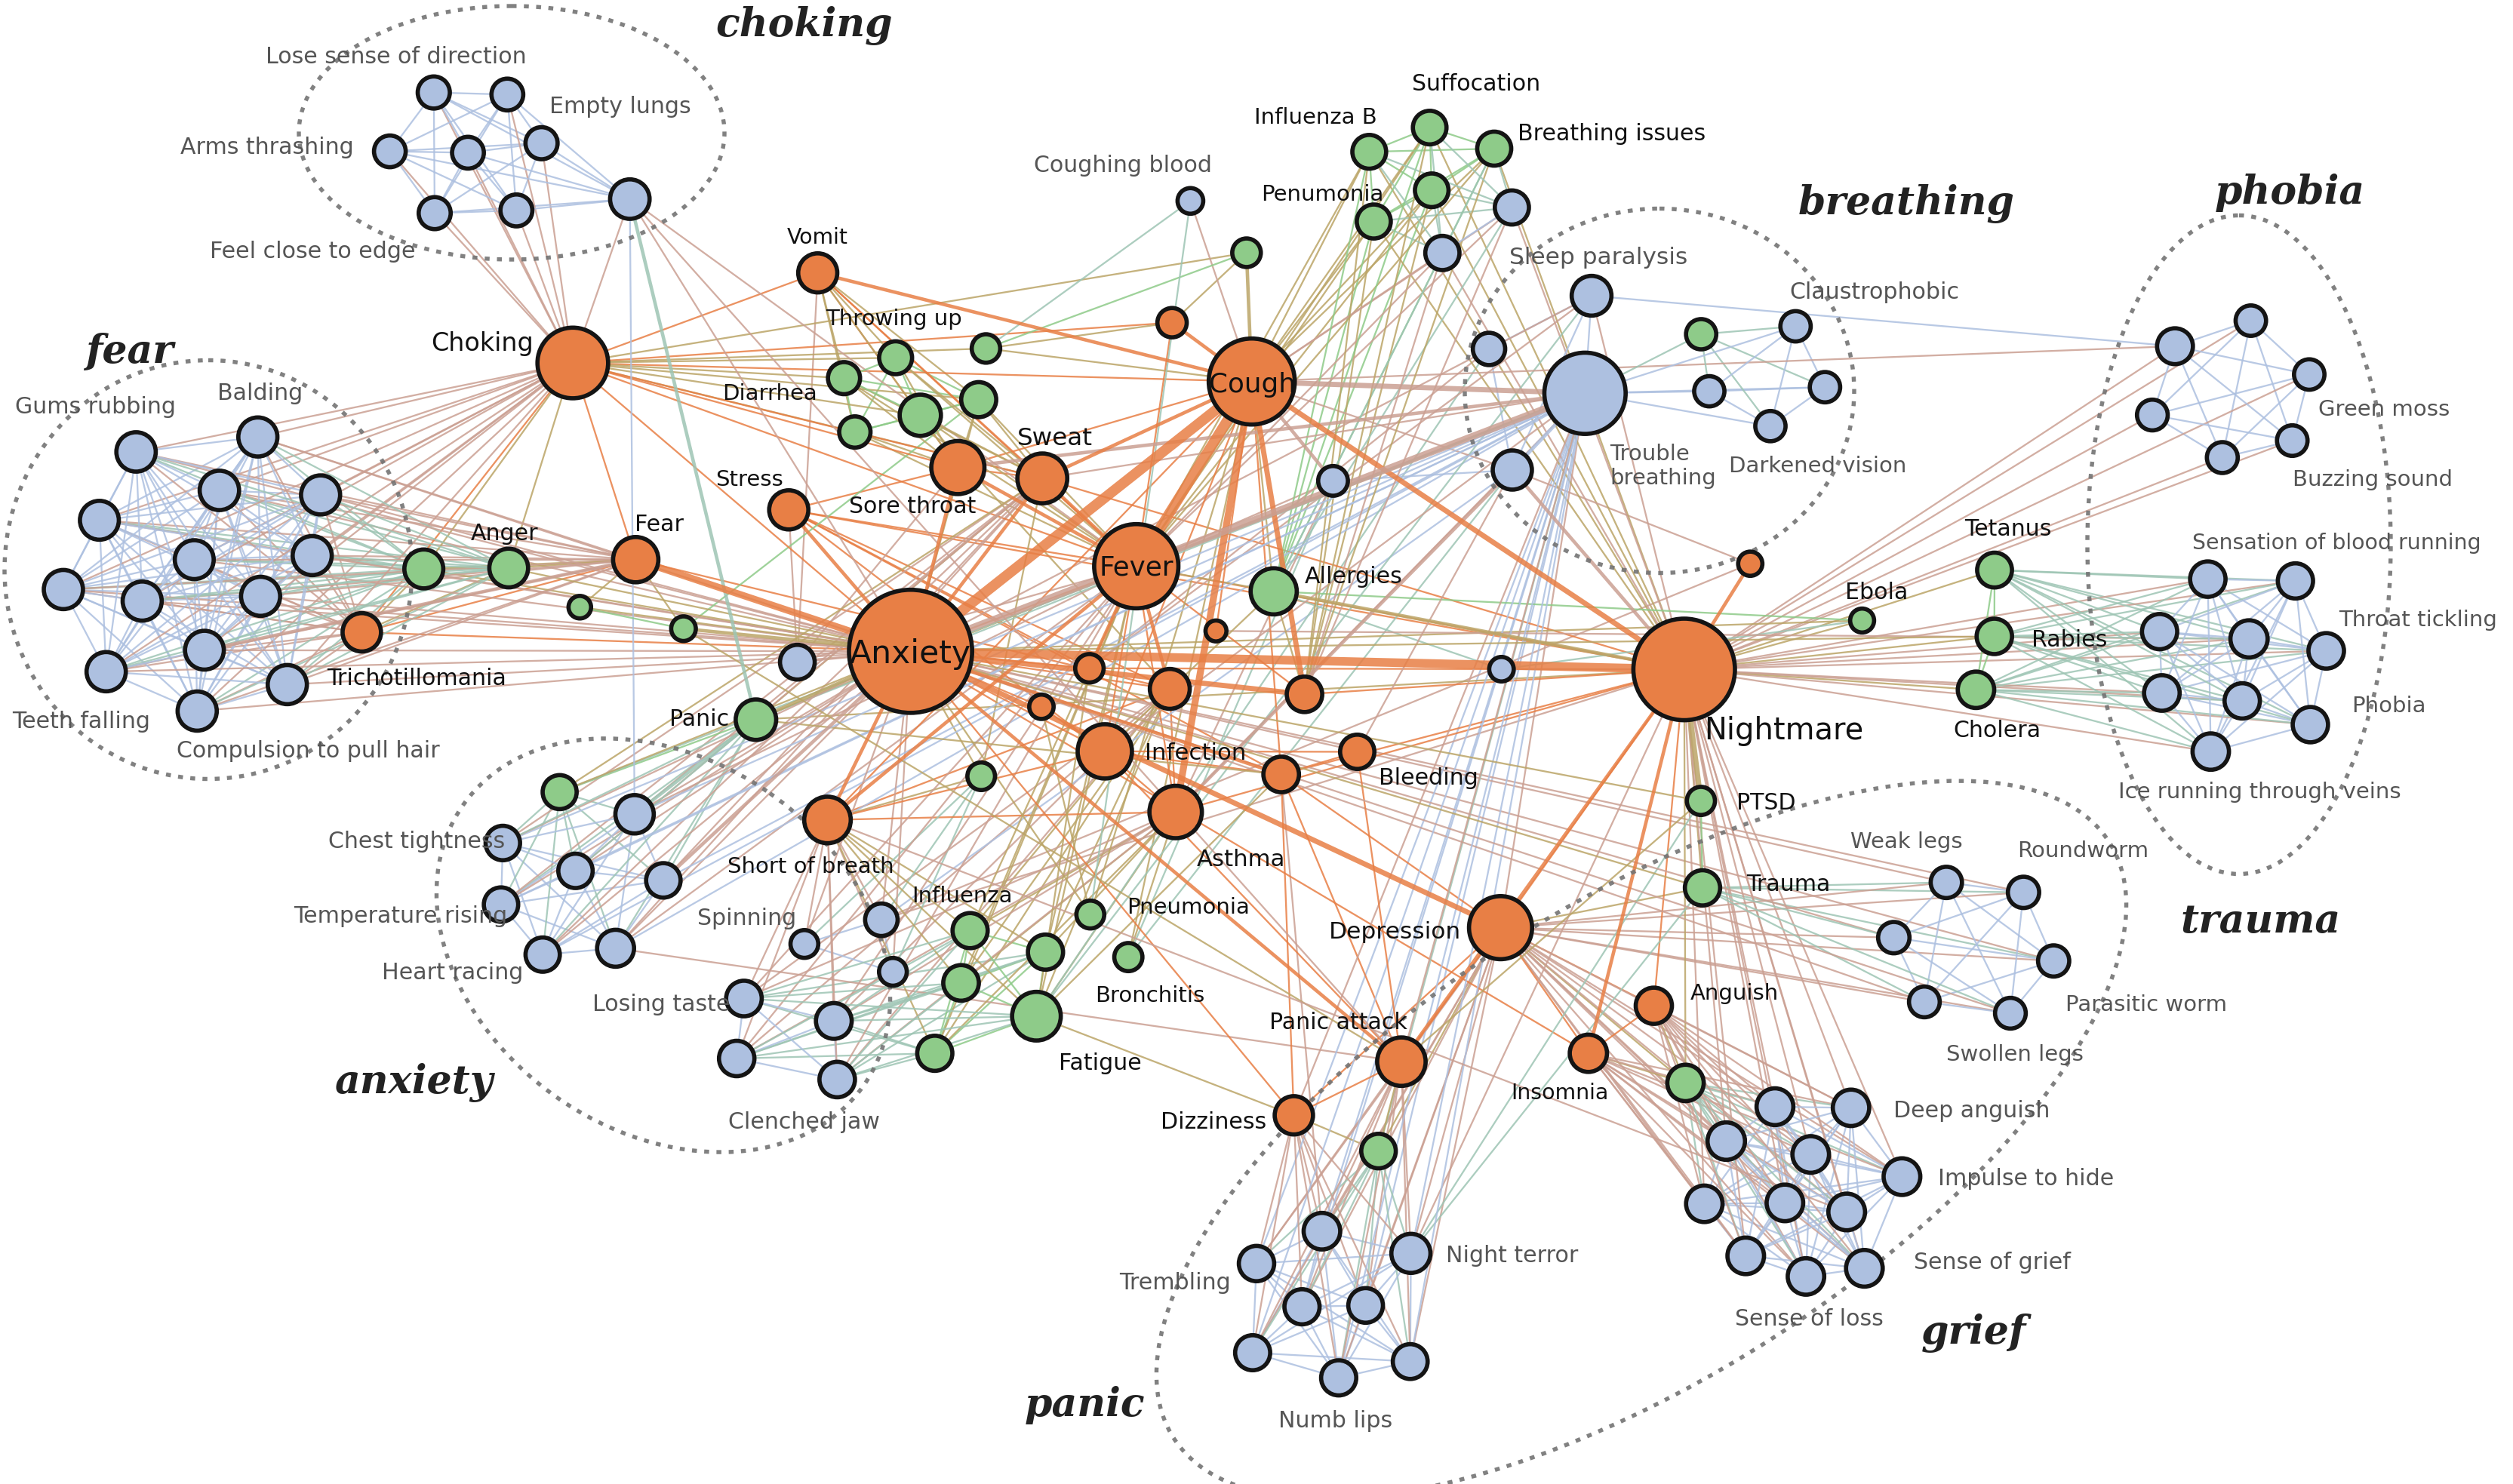

In [3]:
def reproduce_step2_exact_figure3(G, out_png, out_pdf=None, out_svg=None):
    """
    Step 2:
    100% faithful reproduction of Figure 3 matching the exact 154-node subgraph from
    `co_occurrence_graph.csv`, Gephi coordinates, PageRank radii, mixed-color edges,
    74 node labels, 6 dotted cluster ellipses, and 8 italic semantic group headers.
    """
    node_info = {
        name: {"idx": idx, "cx": cx, "cy": cy, "rad": rad, "cls": cls}
        for idx, name, cx, cy, rad, cls in FIG3_NODES
    }
    G_sub = G.subgraph(node_info.keys()).copy()

    # Figure 3 native aspect ratio (1110 x 656)
    fig, ax = plt.subplots(figsize=(11.10, 6.56), dpi=300)
    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")
    fig.subplots_adjust(left=0, right=1, top=1, bottom=0)
    ax.set_xlim(0, 1110)
    ax.set_ylim(656, 0)
    ax.axis("off")

    # 1. Draw all 992 induced edges from co_occurrence_graph.csv with Gephi 50/50 RGB color mixing
    segments, edge_colors, edge_widths = [], [], []
    sorted_edges = sorted(G_sub.edges(data=True), key=lambda x: x[2].get("weight", 1.0))
    for u, v, d in sorted_edges:
        cu, cv = node_info[u], node_info[v]
        segments.append([(cu["cx"], cu["cy"]), (cv["cx"], cv["cy"])])
        col_u = COLOR_MAP[cu["cls"]]
        col_v = COLOR_MAP[cv["cls"]]
        mix_col = 0.5 * (col_u + col_v)
        edge_colors.append((*mix_col, 0.85))
        w = d.get("weight", 1.0)
        lw = 0.55 + 0.55 * (w - 1.0)
        edge_widths.append(min(lw, 4.2))

    lc = LineCollection(segments, colors=edge_colors, linewidths=edge_widths, zorder=1)
    ax.add_collection(lc)

    # 2. Draw the 6 dotted cluster ellipses
    ellipses = [
        (226.0, 59.0, 94.0, 56.0, 0.0),
        (92.0, 252.0, 90.0, 92.5, 0.0),
        (293.0, 418.0, 108.0, 82.0, 35.0),
        (733.0, 173.0, 86.0, 80.5, 0.0),
        (989.0, 241.0, 67.0, 145.5, 0.0),
        (725.0, 504.0, 245.0, 105.0, -32.5),
    ]
    for xc, yc, rx, ry, ang in ellipses:
        el = Ellipse(
            (xc, yc), width=2 * rx, height=2 * ry, angle=ang,
            edgecolor=(0.45, 0.45, 0.45, 0.9), facecolor="none",
            linestyle=(0, (1.2, 1.8)), linewidth=1.3, zorder=2
        )
        ax.add_patch(el)

    # 3. Draw all 154 nodes with exact PageRank-derived radii and black borders
    for _, name, cx, cy, rad, cls in FIG3_NODES:
        circ = Circle(
            (cx, cy), radius=rad,
            facecolor=COLOR_MAP[cls], edgecolor=(0.08, 0.08, 0.08),
            linewidth=1.35, zorder=3
        )
        ax.add_patch(circ)

    # 4. Draw all 74 node labels (black for equally/waking-prevalent, grey for dream-prevalent)
    B = "#111111"
    G_TXT = "#555555"
    labels_74 = [
        # Choking cluster (top-left)
        (175, 25, "Lose sense of direction", G_TXT, 7.2, "center", "center", "normal"),
        (274, 47, "Empty lungs", G_TXT, 7.2, "center", "center", "normal"),
        (118, 65, "Arms thrashing", G_TXT, 7.2, "center", "center", "normal"),
        (138, 111, "Feel close to edge", G_TXT, 7.2, "center", "center", "normal"),
        (213, 152, "Choking", B, 8.0, "center", "center", "normal"),

        # Fear cluster (far-left)
        (42, 180, "Gums rubbing", G_TXT, 7.2, "center", "center", "normal"),
        (115, 174, "Balding", G_TXT, 7.2, "center", "center", "normal"),
        (36, 319, "Teeth falling", G_TXT, 7.2, "center", "center", "normal"),
        (136, 332, "Compulsion to pull hair", G_TXT, 7.2, "center", "center", "normal"),
        (184, 300, "Trichotillomania", B, 7.2, "center", "center", "normal"),
        (223, 236, "Anger", B, 7.2, "center", "center", "normal"),
        (291, 232, "Fear", B, 7.2, "center", "center", "normal"),

        # Vomit / Diarrhea / Throwing up / Sore throat / Sweat / Stress / Anxiety / Panic
        (361, 105, "Vomit", B, 6.8, "center", "center", "normal"),
        (395, 141, "Throwing up", B, 7.0, "center", "center", "normal"),
        (340, 174, "Diarrhea", B, 7.0, "center", "center", "normal"),
        (331, 212, "Stress", B, 7.0, "center", "center", "normal"),
        (403, 224, "Sore throat", B, 7.2, "center", "center", "normal"),
        (466, 194, "Sweat", B, 7.8, "center", "center", "normal"),
        (402, 289, "Anxiety", B, 10.2, "center", "center", "normal"),
        (309, 318, "Panic", B, 7.2, "center", "center", "normal"),

        # Anxiety cluster (bottom-left)
        (184, 372, "Chest tightness", G_TXT, 7.2, "center", "center", "normal"),
        (177, 405, "Temperature rising", G_TXT, 7.2, "center", "center", "normal"),
        (200, 430, "Heart racing", G_TXT, 7.2, "center", "center", "normal"),
        (358, 383, "Short of breath", B, 7.0, "center", "center", "normal"),
        (330, 406, "Spinning", G_TXT, 7.2, "center", "center", "normal"),
        (292, 444, "Losing taste", G_TXT, 7.2, "center", "center", "normal"),
        (355, 496, "Clenched jaw", G_TXT, 7.2, "center", "center", "normal"),

        # Influenza / Pneumonia / Bronchitis / Fatigue
        (425, 396, "Influenza", B, 7.0, "center", "center", "normal"),
        (525, 401, "Pneumonia", B, 7.0, "center", "center", "normal"),
        (508, 440, "Bronchitis", B, 7.0, "center", "center", "normal"),
        (486, 470, "Fatigue", B, 7.2, "center", "center", "normal"),

        # Central Cough / Fever / Allergies / Infection / Asthma / Bleeding
        (496, 73, "Coughing blood", G_TXT, 7.2, "center", "center", "normal"),
        (581, 52, "Influenza B", B, 7.0, "center", "center", "normal"),
        (652, 37, "Suffocation", B, 7.2, "center", "center", "normal"),
        (712, 59, "Breathing issues", B, 7.2, "center", "center", "normal"),
        (584, 86, "Penumonia", B, 7.0, "center", "center", "normal"),  # Exact spelling in Figure 3
        (553, 170, "Cough", B, 8.6, "center", "center", "normal"),
        (502, 251, "Fever", B, 8.6, "center", "center", "normal"),
        (598, 255, "Allergies", B, 7.2, "center", "center", "normal"),
        (528, 333, "Infection", B, 7.4, "center", "center", "normal"),
        (548, 380, "Asthma", B, 7.4, "center", "center", "normal"),
        (631, 344, "Bleeding", B, 7.2, "center", "center", "normal"),

        # Breathing cluster (top-right-center)
        (706, 114, "Sleep paralysis", G_TXT, 7.5, "center", "center", "normal"),
        (828, 129, "Claustrophobic", G_TXT, 7.2, "center", "center", "normal"),
        (711, 206, "Trouble\nbreathing", G_TXT, 7.0, "left", "center", "normal"),
        (803, 206, "Darkened vision", G_TXT, 7.0, "center", "center", "normal"),

        # Nightmare / Ebola / PTSD / Trauma / Depression / Panic attack / Dizziness
        (829, 262, "Ebola", B, 7.2, "center", "center", "normal"),
        (788, 323, "Nightmare", B, 9.6, "center", "center", "normal"),
        (780, 355, "PTSD", B, 7.2, "center", "center", "normal"),
        (790, 391, "Trauma", B, 7.2, "center", "center", "normal"),
        (616, 412, "Depression", B, 7.5, "center", "center", "normal"),
        (591, 452, "Panic attack", B, 7.2, "center", "center", "normal"),
        (536, 496, "Dizziness", B, 7.2, "center", "center", "normal"),

        # Panic bottom cluster
        (519, 567, "Trembling", G_TXT, 7.2, "center", "center", "normal"),
        (668, 555, "Night terror", G_TXT, 7.2, "center", "center", "normal"),
        (590, 628, "Numb lips", G_TXT, 7.2, "center", "center", "normal"),

        # Grief cluster
        (766, 439, "Anguish", B, 7.0, "center", "center", "normal"),
        (689, 483, "Insomnia", B, 6.8, "center", "center", "normal"),
        (871, 491, "Deep anguish", G_TXT, 7.2, "center", "center", "normal"),
        (895, 521, "Impulse to hide", G_TXT, 7.2, "center", "center", "normal"),
        (880, 558, "Sense of grief", G_TXT, 7.2, "center", "center", "normal"),
        (799, 583, "Sense of loss", G_TXT, 7.2, "center", "center", "normal"),

        # Trauma right cluster
        (842, 372, "Weak legs", G_TXT, 7.0, "center", "center", "normal"),
        (920, 376, "Roundworm", G_TXT, 7.0, "center", "center", "normal"),
        (948, 444, "Parasitic worm", G_TXT, 7.0, "center", "center", "normal"),
        (890, 466, "Swollen legs", G_TXT, 7.0, "center", "center", "normal"),

        # Phobia cluster (far-right)
        (1053, 181, "Green moss", G_TXT, 7.0, "center", "center", "normal"),
        (1048, 212, "Buzzing sound", G_TXT, 7.0, "center", "center", "normal"),
        (887, 234, "Tetanus", B, 7.2, "center", "center", "normal"),
        (914, 283, "Rabies", B, 7.2, "center", "center", "normal"),
        (882, 323, "Cholera", B, 7.2, "center", "center", "normal"),
        (1032, 240, "Sensation of blood running", G_TXT, 6.8, "center", "center", "normal"),
        (1068, 274, "Throat tickling", G_TXT, 7.0, "center", "center", "normal"),
        (1055, 312, "Phobia", G_TXT, 7.0, "center", "center", "normal"),
        (998, 350, "Ice running through veins", G_TXT, 7.0, "center", "center", "normal"),
    ]

    for x, y, txt, col, fs, ha, va, wt in labels_74:
        ax.text(
            x, y, txt, color=col, fontsize=fs, fontfamily="sans-serif",
            ha=ha, va=va, fontweight=wt, zorder=4
        )

    # 5. Draw the 8 italic group headers at their exact PDF stream coordinates
    group_headers = [
        (316.2, 19.9, "choking"),
        (37.7, 163.9, "fear"),
        (147.8, 487.1, "anxiety"),
        (452.5, 629.3, "panic"),
        (848.6, 597.6, "grief"),
        (963.0, 415.7, "trauma"),
        (978.4, 93.6, "phobia"),
        (794.2, 98.7, "breathing"),
    ]
    for x, y, txt in group_headers:
        ax.text(
            x, y, txt, color="#222222", fontsize=12.5, fontfamily="serif",
            fontstyle="italic", fontweight="bold", ha="left", va="bottom", zorder=5
        )

    fig.savefig(out_png, dpi=300)
    if out_pdf:
        fig.savefig(out_pdf)
    if out_svg:
        fig.savefig(out_svg)
    plt.close(fig)
    print(f"Saved Step 2 exact Figure 3 reproduction to: {out_png}")

reproduce_step2_exact_figure3(G, 'figure3_reproduced.png', 'figure3_reproduced.pdf', 'figure3_reproduced.svg')